# Notebook 07 — Análises complementares

| Seção | Conteúdo |
| --- | --- |
| 1 | Distribuição dos estudantes nos níveis da escala de proficiência do SAEB |
| 2 | Língua falada em casa e proficiência dos estudantes indígenas |
| 3 | Diferenças raciais dentro das escolas e entre escolas |
| 4 | Diagnóstico dos sinais inesperados: incentivo dos responsáveis e trabalho doméstico |
| 5 | Tamanho de efeito da Q23b por categoria |

**Entradas:** `base_analitica.parquet` e `saeb2023_mt_bruta_completa.csv` (apenas para a língua falada em casa, que não está na base analítica). **Saídas:** `tabelas_complementares.xlsx` e `figura_niveis_proficiencia.png`.

## 0. Configuração

In [1]:
import sys, numpy as np, pandas as pd
import statsmodels, statsmodels.formula.api as smf
import matplotlib, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PASTA = '/content/drive/MyDrive/dissertacao/'   # ajuste para a sua pasta
except ImportError:
    PASTA = './'

FATOR_SAEB = 55.093
print({'python': sys.version.split()[0], 'pandas': pd.__version__, 'statsmodels': statsmodels.__version__})
base = pd.read_parquet(PASTA + 'base_analitica.parquet').reset_index(drop=True)
assert len(base) == 22996
TABELAS = {}

def fmt_p(p):
    return '< 0,001' if p < 0.001 else f'{p:.3f}'.replace('.', ',')
def ajustar(f, dados):
    return smf.ols(f, dados).fit(cov_type='cluster', cov_kwds={'groups': dados['id_escola']}, use_t=True)

ATRIB = ("C(sexo, Treatment('Masculino')) + C(raca_cor, Treatment('Branca')) + "
         "C(pretensao_futura, Treatment('Somente estudar')) + idade + reprovacao + aluno_motivacao_aplicar_aprendizado + "
         "tempo_estudos + tempo_cursos + tempo_trabalho_domestico + tempo_trabalho + mora_mae + mora_pai + "
         "escolaridade_mae + escolaridade_pai + responsaveis_incentivam_estudo + responsaveis_conversam_escola + "
         "qtd_computadores + possui_wifi + possui_escrivaninha + possui_casa_quarto_individual")
CONTROLES = ("em_integrado + nao_sabe_escolaridade_mae + nao_sabe_escolaridade_pai + ausente_escolaridade_mae + "
             "ausente_escolaridade_pai + ausente_aluno_motivacao_aplicar_aprendizado + ausente_mora_mae + "
             "ausente_mora_pai + n_itens_ausentes")
FORMULA = 'proficiencia ~ ' + ATRIB + ' + ' + CONTROLES
RACAS = ['Parda', 'Preta', 'Amarela', 'Indígena']
termo_raca = lambda r: f"C(raca_cor, Treatment('Branca'))[T.{r}]"

Mounted at /content/drive
{'python': '3.13.16', 'pandas': '2.2.3', 'statsmodels': '0.15.0'}


## 1. Níveis da escala de proficiência

Escala de Língua Portuguesa da 3ª série do Ensino Médio (INEP): nível 0 abaixo de 225 pontos; níveis de 25 em 25 pontos (nível 1: 225 a menos de 250; nível 2: 250 a menos de 275, até o nível nível 8: 400 ou mais). A descrição pedagógica de cada nível está no documento oficial do INEP e deve acompanhar a interpretação.

  Nível Faixa (pontos)  Estudantes    %  % acumulado
Nível 0  abaixo de 225        4895 21.3         21.3
Nível 1    225 a < 250        3226 14.0         35.3
Nível 2    250 a < 275        3832 16.7         52.0
Nível 3    275 a < 300        4190 18.2         70.2
Nível 4    300 a < 325        3575 15.5         85.7
Nível 5    325 a < 350        2199  9.6         95.3
Nível 6    350 a < 375         867  3.8         99.1
Nível 7    375 a < 400         198  0.9        100.0
Nível 8    400 ou mais          14  0.1        100.1

Percentual de estudantes em cada nível, por grupo:
        Variável               Grupo     N  Abaixo de 250 pontos (%)  Nível 0  Nível 1  Nível 2  Nível 3  Nível 4  Nível 5  Nível 6  Nível 7  Nível 8
        Raça/cor             Amarela   512                      43.4     26.0     17.4     15.6     19.3     13.3      6.2      1.8      0.4      0.0
        Raça/cor              Branca  7039                      27.2     15.3     11.9     14.8     18.8     18.6     

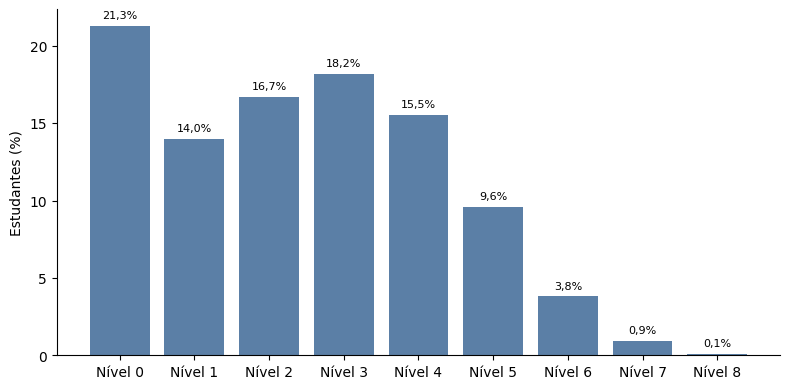

In [2]:
cortes = [-np.inf, 225, 250, 275, 300, 325, 350, 375, 400, np.inf]
rotulos = [f'Nível {i}' for i in range(9)]
base['nivel_saeb'] = pd.cut(base['proficiencia_saeb'], cortes, right=False, labels=rotulos)

geral = base['nivel_saeb'].value_counts().reindex(rotulos)
niveis = pd.DataFrame({'Nível': rotulos, 'Faixa (pontos)': ['abaixo de 225'] + [f'{a} a < {a + 25}' for a in range(225, 400, 25)] + ['400 ou mais'],
                       'Estudantes': geral.values, '%': (100 * geral / len(base)).round(1).values})
niveis['% acumulado'] = niveis['%'].cumsum().round(1)
TABELAS['Níveis geral'] = niveis
print(niveis.to_string(index=False))

grupos = []
for var, rot in [('raca_cor', 'Raça/cor'), ('sexo', 'Sexo'), ('pretensao_futura', 'Pretensão futura')]:
    t = pd.crosstab(base[var], base['nivel_saeb'], normalize='index').reindex(columns=rotulos) * 100
    t.insert(0, 'N', base[var].value_counts())
    t.insert(0, 'Variável', rot)
    grupos.append(t.round(1).reset_index().rename(columns={var: 'Grupo'}))
grupos = pd.concat(grupos, ignore_index=True)
grupos['Abaixo de 250 pontos (%)'] = (grupos['Nível 0'] + grupos['Nível 1']).round(1)
TABELAS['Níveis por grupo'] = grupos
print('\nPercentual de estudantes em cada nível, por grupo:')
print(grupos[['Variável', 'Grupo', 'N', 'Abaixo de 250 pontos (%)'] + rotulos].to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(rotulos, niveis['%'], color='#5b7fa6')
for b, v in zip(barras, niveis['%']):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.5, f'{v:.1f}%'.replace('.', ','), ha='center', fontsize=8)
ax.set_ylabel('Estudantes (%)')
ax.set_yticks(range(0, 25, 5))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(PASTA + 'figura_niveis_proficiencia.png', dpi=300)
plt.show()

## 2. Língua falada em casa e proficiência dos estudantes indígenas

Pergunta do questionário (Q03): "Qual língua que seus pais falam com mais frequência em casa?". Português (A), espanhol (B), língua de sinais (C) ou outra língua (D). Entre estudantes indígenas, "outra língua" indica, provavelmente, uma língua indígena. Esta análise examina a hipótese de que parte da diferença de proficiência dos estudantes indígenas numa prova de leitura em português esteja associada ao português não ser a língua de casa. O número de casos é pequeno, e os resultados são exploratórios.

In [3]:
bruta = pd.read_csv(PASTA + 'saeb2023_mt_bruta_completa.csv', usecols=['id_aluno', 'idioma_domicilio'], dtype=str)
bruta['id_aluno'] = pd.to_numeric(bruta['id_aluno'])
base = base.merge(bruta, on='id_aluno', how='left')
mapa = {'A': 'Português', 'B': 'Espanhol', 'C': 'Língua de sinais', 'D': 'Outra língua'}
base['lingua_casa'] = base['idioma_domicilio'].map(mapa).fillna('Sem resposta')
cruz = pd.crosstab(base['raca_cor'], base['lingua_casa'])
print(cruz.to_string())
TABELAS['Língua por raça'] = cruz.reset_index()

ind = base[(base.raca_cor == 'Indígena') & base.lingua_casa.isin(['Português', 'Outra língua'])]
desc = ind.groupby('lingua_casa')['proficiencia_saeb'].agg(['size', 'mean', 'std']).round(1)
r = ajustar("proficiencia ~ C(lingua_casa, Treatment('Português'))", ind)
t = "C(lingua_casa, Treatment('Português'))[T.Outra língua]"
ic = r.conf_int().loc[t] * FATOR_SAEB
print('\nEstudantes indígenas, por língua falada em casa:')
print(desc.rename(columns={'size': 'N', 'mean': 'Média (pontos SAEB)', 'std': 'Desvio-padrão'}).to_string())
print(f'Diferença (outra língua − português): {r.params[t] * FATOR_SAEB:.1f} pontos '
      f'(IC 95%: {ic[0]:.1f} a {ic[1]:.1f}; p {fmt_p(r.pvalues[t])})')

base['lingua_nao_portugues'] = base['lingua_casa'].isin(['Espanhol', 'Língua de sinais', 'Outra língua']).astype(int)
base['lingua_sem_resposta'] = (base['lingua_casa'] == 'Sem resposta').astype(int)
m0 = ajustar(FORMULA, base)
m1 = ajustar(FORMULA + ' + lingua_nao_portugues + lingua_sem_resposta', base)
comp = pd.DataFrame({'Raça/cor (ref.: branca)': RACAS,
                     'Modelo principal (pontos SAEB)': [round(m0.params[termo_raca(x)] * FATOR_SAEB, 1) for x in RACAS],
                     '+ língua falada em casa (pontos SAEB)': [round(m1.params[termo_raca(x)] * FATOR_SAEB, 1) for x in RACAS]})
TABELAS['Língua e indígenas'] = pd.concat([desc.reset_index(), comp], axis=1)
print('\nCoeficientes de raça/cor com e sem a língua falada em casa no modelo:')
print(comp.to_string(index=False))
print(f"Língua de casa diferente do português: {m1.params['lingua_nao_portugues'] * FATOR_SAEB:.1f} pontos "
      f"(p {fmt_p(m1.pvalues['lingua_nao_portugues'])})")

lingua_casa  Espanhol  Língua de sinais  Outra língua  Português  Sem resposta
raca_cor                                                                      
Amarela             8                 2             4        495             3
Branca             22                10            20       6975            12
Indígena            2                 2            34        210             1
Parda              53                10             9      11860            30
Preta              17                 6            21       3180            10

Estudantes indígenas, por língua falada em casa:
                N  Média (pontos SAEB)  Desvio-padrão
lingua_casa                                          
Outra língua   34                222.2           44.5
Português     210                240.5           45.4
Diferença (outra língua − português): -18.4 pontos (IC 95%: -34.0 a -2.8; p 0,021)

Coeficientes de raça/cor com e sem a língua falada em casa no modelo:
Raça/cor (ref.: branca)  Mo

## 3. Diferenças raciais dentro das escolas e entre escolas

A diferença de proficiência entre grupos raciais pode ocorrer **entre escolas** (estudantes negros e indígenas concentrados em escolas com resultados mais baixos) ou **dentro das escolas** (diferenças entre colegas da mesma escola). Para separar as duas, os modelos são estimados com e sem efeitos fixos de escola. Com efeitos fixos, cada estudante é comparado apenas aos colegas da própria escola; a diferença que permanece é a diferença **dentro** das escolas.

O código da escola é mascarado nos microdados, o que impede identificar escolas indígenas pelo Censo Escolar. A concentração dos estudantes indígenas por escola é descrita como aproximação.

In [4]:
modelos = {'Bruta (sem controles)': 'proficiencia ~ ' + "C(raca_cor, Treatment('Branca'))",
           'Bruta, dentro das escolas': 'proficiencia ~ ' + "C(raca_cor, Treatment('Branca'))" + ' + C(id_escola)',
           'Com controles': FORMULA,
           'Com controles, dentro das escolas': FORMULA + ' + C(id_escola)'}
res = {nome: ajustar(f, base) for nome, f in modelos.items()}
linhas = []
for rc in RACAS:
    lin = {'Raça/cor (ref.: branca)': rc}
    for nome, r in res.items():
        lin[nome] = f"{r.params[termo_raca(rc)] * FATOR_SAEB:.1f}".replace('.', ',') + \
                    ('' if r.pvalues[termo_raca(rc)] < 0.05 else ' (ns)')
    bruta_t = res['Bruta (sem controles)'].params[termo_raca(rc)]
    dentro_t = res['Bruta, dentro das escolas'].params[termo_raca(rc)]
    lin['Parcela da diferença bruta que ocorre dentro das escolas (%)'] = round(100 * dentro_t / bruta_t, 0)
    linhas.append(lin)
dentro = pd.DataFrame(linhas)
TABELAS['Dentro e entre escolas'] = dentro
print('Diferença em relação aos estudantes brancos (pontos SAEB); (ns) = não significativo.')
print(dentro.to_string(index=False))

conc = base.groupby('id_escola').agg(n=('raca_cor', 'size'), pct_ind=('raca_cor', lambda s: 100 * (s == 'Indígena').mean()))
base = base.merge(conc['pct_ind'].rename('pct_indigenas_escola'), left_on='id_escola', right_index=True)
ind = base[base.raca_cor == 'Indígena']
faixas = pd.cut(ind['pct_indigenas_escola'], [0, 10, 50, 100.1], right=False,
                labels=['menos de 10%', '10% a 49%', '50% ou mais'])
t = ind.groupby(faixas, observed=False).agg(Estudantes=('proficiencia_saeb', 'size'),
                                            Escolas=('id_escola', 'nunique'),
                                            Média=('proficiencia_saeb', 'mean')).round(1)
t.index.name = 'Participação de indígenas na escola'
TABELAS['Concentração indígena'] = t.reset_index()
print('\nEstudantes indígenas segundo a participação de indígenas na própria escola:')
print(t.to_string())

Diferença em relação aos estudantes brancos (pontos SAEB); (ns) = não significativo.
Raça/cor (ref.: branca) Bruta (sem controles) Bruta, dentro das escolas Com controles Com controles, dentro das escolas  Parcela da diferença bruta que ocorre dentro das escolas (%)
                  Parda                 -14,7                     -10,8          -8,9                              -7,1                                                          73.0
                  Preta                 -22,1                     -18,0         -12,6                             -10,7                                                          82.0
                Amarela                 -22,5                     -18,6         -13,5                             -12,1                                                          83.0
               Indígena                 -44,4                     -39,1         -27,3                             -26,3                                                          88.0

Estu

## 4. Diagnóstico dos sinais inesperados

Dois atributos têm sinal contrário ao esperado, **responsáveis incentivam o estudo** (negativo) e **trabalho doméstico** (positivo). Cada um é estimado em etapas, para verificar em que momento o sinal aparece e quais variáveis o explicam.

- **Incentivo dos responsáveis.** Hipótese de monitoramento reativo: os responsáveis incentivariam mais quando o estudante tem dificuldades, o que tornaria a associação negativa. A etapa 2 inclui reprovação e tempo de estudos, indicadores de trajetória e de dificuldade.
- **Trabalho doméstico.** Hipótese de composição por sexo: as estudantes dedicam mais tempo ao trabalho doméstico e têm proficiência mais alta. A etapa 2 inclui o sexo.

In [5]:
def etapas(var, passos):
    linhas = []
    for nome, f in passos.items():
        r = ajustar(f, base)
        linhas.append({'Atributo': var, 'Etapa': nome, 'Coeficiente (pontos SAEB)': round(r.params[var] * FATOR_SAEB, 1),
                       'p-valor': fmt_p(r.pvalues[var])})
    return linhas

socio = ('escolaridade_mae + escolaridade_pai + nao_sabe_escolaridade_mae + nao_sabe_escolaridade_pai + '
         'ausente_escolaridade_mae + ausente_escolaridade_pai + qtd_computadores + possui_wifi + '
         "C(raca_cor, Treatment('Branca'))")
v1 = 'responsaveis_incentivam_estudo'
p1 = {'1. Apenas o atributo': f'proficiencia ~ {v1}',
      '2. + reprovação e tempo de estudos': f'proficiencia ~ {v1} + reprovacao + tempo_estudos',
      '3. + condições socioeconômicas e raça/cor': f'proficiencia ~ {v1} + reprovacao + tempo_estudos + {socio}',
      '4. Modelo completo': FORMULA}
v2 = 'tempo_trabalho_domestico'
p2 = {'1. Apenas o atributo': f'proficiencia ~ {v2}',
      '2. + sexo': f"proficiencia ~ {v2} + C(sexo, Treatment('Masculino'))",
      '3. + condições socioeconômicas e raça/cor': f"proficiencia ~ {v2} + C(sexo, Treatment('Masculino')) + {socio}",
      '4. Modelo completo': FORMULA}
diag = pd.DataFrame(etapas(v1, p1) + etapas(v2, p2))
TABELAS['Sinais inesperados'] = diag
print(diag.to_string(index=False))

r = ajustar(f'{v1} ~ reprovacao', base)
print(f'\nIncentivo dos responsáveis entre quem reprovou ao menos uma vez: {base.loc[base.reprovacao > 0, v1].mean():.3f}; '
      f'entre quem nunca reprovou: {base.loc[base.reprovacao == 0, v1].mean():.3f}')
print(f"Trabalho doméstico: meninas {base.loc[base.sexo == 'Feminino', v2].mean():.3f}; "
      f"meninos {base.loc[base.sexo == 'Masculino', v2].mean():.3f}")

                      Atributo                                     Etapa  Coeficiente (pontos SAEB) p-valor
responsaveis_incentivam_estudo                      1. Apenas o atributo                       -1.3   0,041
responsaveis_incentivam_estudo        2. + reprovação e tempo de estudos                       -4.8 < 0,001
responsaveis_incentivam_estudo 3. + condições socioeconômicas e raça/cor                       -5.1 < 0,001
responsaveis_incentivam_estudo                        4. Modelo completo                       -3.8 < 0,001
      tempo_trabalho_domestico                      1. Apenas o atributo                        4.1 < 0,001
      tempo_trabalho_domestico                                 2. + sexo                        2.3 < 0,001
      tempo_trabalho_domestico 3. + condições socioeconômicas e raça/cor                        2.2 < 0,001
      tempo_trabalho_domestico                        4. Modelo completo                        1.4 < 0,001

Incentivo dos responsáveis 

## 5. Tamanho de efeito da Q23b por categoria

Análise de variância da proficiência pelas quatro categorias da Q23b (respostas válidas). eta² = (F × gl entre grupos) ÷ (F × gl entre grupos + gl dentro dos grupos).

In [6]:
from scipy.stats import f_oneway
Q = 'aluno_motivacao_aplicar_aprendizado'
v = base[base['ausente_' + Q] == 0]
F, p = f_oneway(*[g['proficiencia'].values for _, g in v.groupby(Q)])
gl1, gl2 = v[Q].nunique() - 1, len(v) - v[Q].nunique()
eta2 = F * gl1 / (F * gl1 + gl2)
r = ajustar(f'proficiencia ~ C({Q})', v)
R = np.zeros((3, len(r.params)));
for i, n in enumerate([t for t in r.params.index if t.startswith('C(')]): R[i, list(r.params.index).index(n)] = 1
p_clu = float(r.wald_test(R, scalar=True).pvalue)
q15 = pd.DataFrame({'Indicador': ['N (respostas válidas)', 'F', 'gl', 'p-valor (ANOVA)', 'eta²',
                                  'p-valor (erros-padrão agrupados por escola)'],
                    'Valor': [len(v), round(F, 3), f'{gl1} e {gl2}', fmt_p(p), round(eta2, 3), fmt_p(p_clu)]})
TABELAS['Q23b eta2'] = q15
print(q15.to_string(index=False))

                                  Indicador     Valor
                      N (respostas válidas)     22795
                                          F   329.009
                                         gl 3 e 22791
                            p-valor (ANOVA)   < 0,001
                                       eta²     0.042
p-valor (erros-padrão agrupados por escola)   < 0,001


## Exportação

In [7]:
with pd.ExcelWriter(PASTA + 'tabelas_complementares.xlsx') as xw:
    for nome, t in TABELAS.items():
        t.to_excel(xw, sheet_name=nome[:31], index=False)
print('Tabelas salvas em', PASTA + 'tabelas_complementares.xlsx')

Tabelas salvas em /content/drive/MyDrive/dissertacao/tabelas_complementares.xlsx
